# Cognitive Individual Differences in Delay Discounting

## Question

Are individual differences in delay discounting associated with cognitive
capacity and other participant-level characteristics?

This notebook uses the AgeRisk dataset to examine whether estimated
delay-discounting behavior relates to measures such as working memory,
age, numeracy, and self-control.

The primary cognitive variable of interest is working memory, measured
using the automated operation span task.

In [151]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.special import expit

## Load and Clean Delay-Discounting Trials

The AgeRisk delay-discounting task is stored as one E-Prime CSV file per
participant. Each file contains setup rows as well as experimental trials.

Only rows whose E-Prime level begins with `DDList_` are retained. Choices are
recoded so that `1` represents the larger-later option and `0` represents the
smaller-sooner option, matching the coding used in the earlier notebooks.

Delay values are represented in weeks.

In [152]:
# Folder containing one *_DelayDiscounting.csv file per participant.
# Adjust if your local copy of AgeRisk is organized differently.
dd_dir = Path("../data/raw/agerisk/delay_discounting")

delay_map = {
    "Heute": 0,
    "2 Wochen": 2,
    "4 Wochen": 4,
    "6 Wochen": 6
}

dd_files = sorted(
    dd_dir.glob("*_DelayDiscounting.csv")
)

all_trials = []

for path in dd_files:
    participant_df = pd.read_csv(
        path,
        na_values=["NA"]
    )

    trials = participant_df[
        participant_df["Eprime.LevelName"]
        .astype(str)
        .str.startswith("DDList_")
    ].copy()

    trials = trials[
        [
            "ID_eprime",
            "Sample",
            "SSout",
            "SSdel",
            "SSdelNum",
            "LLout",
            "LLdel",
            "LLdelNum",
            "Choice"
        ]
    ]

    all_trials.append(trials)

agerisk_dd = pd.concat(
    all_trials,
    ignore_index=True
)

In [153]:
agerisk_dd = agerisk_dd.rename(
    columns={
        "ID_eprime": "subj_ident",
        "Sample": "trial_idx",
        "SSout": "ss_value",
        "SSdelNum": "ss_delay",
        "LLout": "ll_value",
        "LLdelNum": "ll_delay"
    }
)

agerisk_dd["ss_delay"] = pd.to_numeric(
    agerisk_dd["ss_delay"],
    errors="coerce"
)

agerisk_dd["ll_delay"] = pd.to_numeric(
    agerisk_dd["ll_delay"],
    errors="coerce"
)

agerisk_dd["ss_delay"] = (
    agerisk_dd["ss_delay"]
    .fillna(
        agerisk_dd["SSdel"].map(delay_map)
    )
)

agerisk_dd["ll_delay"] = (
    agerisk_dd["ll_delay"]
    .fillna(
        agerisk_dd["LLdel"].map(delay_map)
    )
)

agerisk_dd["choice"] = (
    agerisk_dd["Choice"]
    .map({
        "SS": 0,
        "LL": 1
    })
)

agerisk_dd = agerisk_dd.drop(
    columns=[
        "Choice",
        "SSdel",
        "LLdel"
    ]
)

numeric_columns = [
    "trial_idx",
    "ss_value",
    "ss_delay",
    "ll_value",
    "ll_delay",
    "choice"
]

for column in numeric_columns:
    agerisk_dd[column] = pd.to_numeric(
        agerisk_dd[column],
        errors="coerce"
    )

### Delay Coding

The raw E-Prime files contained 189 trials in which the numeric delay fields
were represented by `"?"`. These trials were not missing the underlying delay
information: their text labels consistently identified the smaller-sooner
delay as 4 weeks and the larger-later delay as 6 weeks.

Numeric delays were therefore reconstructed from the task's four observed
delay labels (`Heute`, `2 Wochen`, `4 Wochen`, and `6 Wochen`), preserving all
16,000 experimental trials.

## Estimate Individual Discounting Parameters

The same hyperbolic choice model used in the earlier notebooks is now fit
separately to each AgeRisk participant.

For each option, subjective value is modeled as

\[
V = \frac{A}{1 + kD}
\]

where `A` is reward amount, `D` is delay in weeks, and `k` is the participant's
discount rate.

Choice probabilities are modeled using a logistic choice rule based on the
difference between larger-later and smaller-sooner subjective values.

Each participant receives separate estimates of:

- `k`: discount rate
- `β`: choice sensitivity

Because both parameters must be positive, optimization is performed on their
log-transformed values.

In [ ]:
import discounting

# Implementation: src/discounting/fitting.py.
# fit_mle runs L-BFGS-B on log(k) and log(beta) from several starting points
# and keeps the best fit, so a flat region of the likelihood cannot stop the
# optimizer at a false boundary solution.
fit_participant = discounting.fit_mle

In [156]:
fit_rows = []

for subj_ident, participant_df in agerisk_dd.groupby(
    "subj_ident"
):
    fit = fit_participant(
        participant_df
    )

    fit_rows.append(
        {
            "subj_ident": subj_ident,
            "n_trials": len(participant_df),
            **fit
        }
    )

agerisk_params = pd.DataFrame(
    fit_rows
)

display(agerisk_params.head())

,subj_ident,n_trials,estimated_k,estimated_beta,negative_log_likelihood,converged
0,1,80,0.099304,0.927298,29.695419,True
1,2,80,0.007695,1.569222,24.810157,True
2,3,80,0.042799,1.196303,28.560949,True
3,4,80,0.000001,0.807875,29.455108,True
4,5,80,0.234079,1.142972,18.892921,True


In [157]:
k_lower = 1e-6
k_upper = 100

beta_lower = 1e-4
beta_upper = 100

agerisk_params["k_boundary"] = (
    np.isclose(
        agerisk_params["estimated_k"],
        k_lower
    )
    |
    np.isclose(
        agerisk_params["estimated_k"],
        k_upper
    )
)

agerisk_params["beta_boundary"] = (
    np.isclose(
        agerisk_params["estimated_beta"],
        beta_lower
    )
    |
    np.isclose(
        agerisk_params["estimated_beta"],
        beta_upper
    )
)

agerisk_params["any_boundary"] = (
    agerisk_params["k_boundary"]
    | agerisk_params["beta_boundary"]
)

In [158]:
print(
    "k lower boundary:",
    np.isclose(
        agerisk_params["estimated_k"],
        k_lower
    ).sum()
)

print(
    "k upper boundary:",
    np.isclose(
        agerisk_params["estimated_k"],
        k_upper
    ).sum()
)

print(
    "beta lower boundary:",
    np.isclose(
        agerisk_params["estimated_beta"],
        beta_lower
    ).sum()
)

print(
    "beta upper boundary:",
    np.isclose(
        agerisk_params["estimated_beta"],
        beta_upper
    ).sum()
)

print(
    "Any boundary:",
    agerisk_params["any_boundary"].sum()
)

k lower boundary: 39
k upper boundary: 1
beta lower boundary: 0
beta upper boundary: 9
Any boundary: 43


In [159]:
agerisk_params["log_k"] = np.log10(
    agerisk_params["estimated_k"]
)

agerisk_params["log_beta"] = np.log10(
    agerisk_params["estimated_beta"]
)

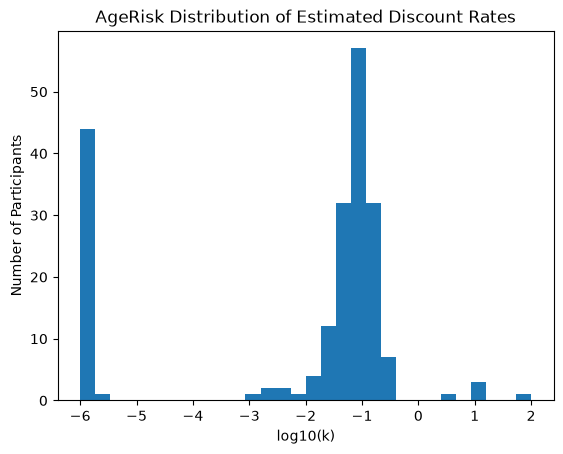

In [160]:
plt.hist(
    agerisk_params["log_k"],
    bins=30
)

plt.xlabel("log10(k)")
plt.ylabel("Number of Participants")
plt.title("AgeRisk Distribution of Estimated Discount Rates")

plt.show()

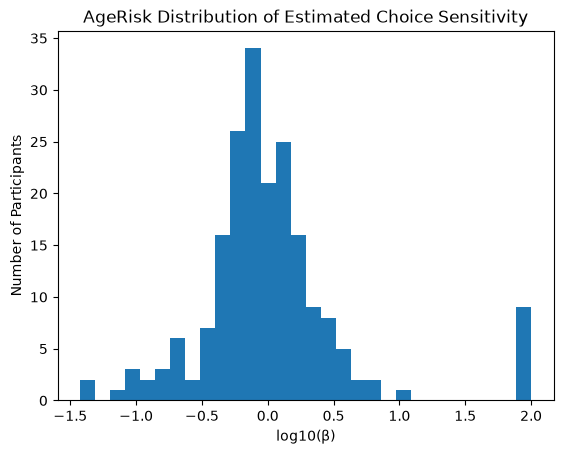

In [161]:
plt.hist(
    agerisk_params["log_beta"],
    bins=30
)

plt.xlabel("log10(β)")
plt.ylabel("Number of Participants")
plt.title("AgeRisk Distribution of Estimated Choice Sensitivity")

plt.show()

### Parameter Identification

All 200 participant-level optimizations converged successfully. However, 43
participants had at least one parameter estimate at an optimization boundary.

The most common case was the lower bound of the discount-rate parameter,
with 39 participants estimated at approximately zero discounting. Nine
participants reached the upper bound of the choice-sensitivity parameter,
and one participant reached the upper bound of the discount-rate parameter.

Because boundary estimates are not well identified, subsequent analyses of
individual differences in `k` and `β` focus primarily on the 157 participants
with interior parameter estimates.

In [162]:
ospan_path = Path(
    "../data/raw/agerisk/automated_operation_span.csv"
)

ospan_df = pd.read_csv(
    ospan_path,
    na_values=["NA"]
)

In [163]:
participants_key_path = Path(
    "../data/raw/agerisk/participants_key.csv"
)

participants_key = pd.read_csv(
    participants_key_path,
    na_values=["NA"]
)

In [164]:
participant_key_clean = (
    participants_key[
        [
            "id",
            "eprime_id",
            "gender"
        ]
    ]
    .rename(
        columns={
            "eprime_id": "subj_ident"
        }
    )
)

In [165]:
cognitive_df = agerisk_params.merge(
    participant_key_clean,
    on="subj_ident",
    how="inner",
    validate="one_to_one"
)

In [166]:
cognitive_df = cognitive_df.merge(
    ospan_df[
        [
            "id",
            "ospan_score"
        ]
    ],
    on="id",
    how="inner",
    validate="one_to_one"
)

In [167]:
cognitive_interior = cognitive_df[
    ~cognitive_df["any_boundary"]
].copy()

print(
    "Interior participants with cognitive data:",
    len(cognitive_interior)
)

Interior participants with cognitive data: 157


count    157.000000
mean      28.146497
std       15.524511
min        2.000000
25%       16.000000
50%       26.000000
75%       39.000000
max       62.000000
Name: ospan_score, dtype: float64

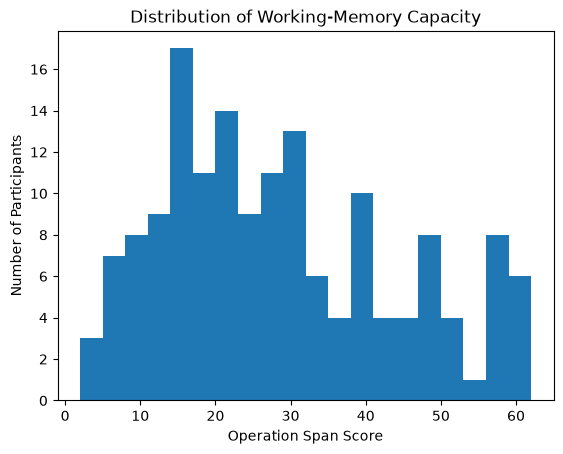

In [168]:
display(
    cognitive_interior["ospan_score"].describe()
)

plt.hist(
    cognitive_interior["ospan_score"],
    bins=20
)

plt.xlabel("Operation Span Score")
plt.ylabel("Number of Participants")
plt.title("Distribution of Working-Memory Capacity")

plt.show()

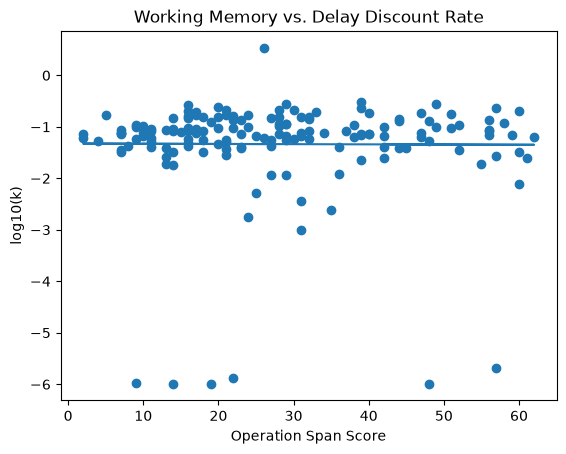

In [169]:
x = cognitive_interior["ospan_score"]
y = cognitive_interior["log_k"]

slope, intercept = np.polyfit(
    x,
    y,
    1
)

plt.scatter(x, y)

plt.plot(
    x,
    slope * x + intercept
)

plt.xlabel("Operation Span Score")
plt.ylabel("log10(k)")
plt.title(
    "Working Memory vs. Delay Discount Rate"
)

plt.show()

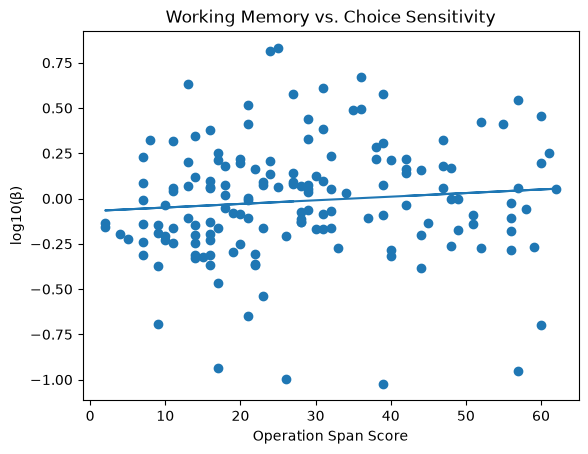

In [170]:
x = cognitive_interior["ospan_score"]
y = cognitive_interior["log_beta"]

slope, intercept = np.polyfit(
    x,
    y,
    1
)

plt.scatter(x, y)

plt.plot(
    x,
    slope * x + intercept
)

plt.xlabel("Operation Span Score")
plt.ylabel("log10(β)")
plt.title(
    "Working Memory vs. Choice Sensitivity"
)

plt.show()

In [171]:
from scipy.stats import pearsonr, spearmanr

pearson_k = pearsonr(
    cognitive_interior["ospan_score"],
    cognitive_interior["log_k"]
)

pearson_beta = pearsonr(
    cognitive_interior["ospan_score"],
    cognitive_interior["log_beta"]
)

spearman_k = spearmanr(
    cognitive_interior["ospan_score"],
    cognitive_interior["log_k"]
)

spearman_beta = spearmanr(
    cognitive_interior["ospan_score"],
    cognitive_interior["log_beta"]
)

print(
    "Pearson OSPAN vs log10(k):",
    pearson_k
)

print(
    "Pearson OSPAN vs log10(beta):",
    pearson_beta
)

print(
    "Spearman OSPAN vs log10(k):",
    spearman_k
)

print(
    "Spearman OSPAN vs log10(beta):",
    spearman_beta
)

Pearson OSPAN vs log10(k): PearsonRResult(statistic=np.float64(-0.0059710176553694335), pvalue=np.float64(0.9408357865706921))
Pearson OSPAN vs log10(beta): PearsonRResult(statistic=np.float64(0.09665792931929584), pvalue=np.float64(0.22848749228472184))
Spearman OSPAN vs log10(k): SignificanceResult(statistic=np.float64(0.03441785500781809), pvalue=np.float64(0.6686983585739127))
Spearman OSPAN vs log10(beta): SignificanceResult(statistic=np.float64(0.1712004819019739), pvalue=np.float64(0.03204509804102057))


In [172]:
choice_behavior = (
    agerisk_dd
    .groupby("subj_ident")["choice"]
    .mean()
    .reset_index(name="ll_choice_rate")
)

choice_behavior["ss_choice_rate"] = (
    1 - choice_behavior["ll_choice_rate"]
)

In [173]:
cognitive_df = cognitive_df.merge(
    choice_behavior[
        [
            "subj_ident",
            "ss_choice_rate"
        ]
    ],
    on="subj_ident",
    how="left",
    validate="one_to_one"
)

In [174]:
ospan_ss_pearson = pearsonr(
    cognitive_df["ospan_score"],
    cognitive_df["ss_choice_rate"]
)

ospan_ss_spearman = spearmanr(
    cognitive_df["ospan_score"],
    cognitive_df["ss_choice_rate"]
)

print(
    "Pearson OSPAN vs SS choice rate:",
    ospan_ss_pearson
)

print(
    "Spearman OSPAN vs SS choice rate:",
    ospan_ss_spearman
)

Pearson OSPAN vs SS choice rate: PearsonRResult(statistic=np.float64(-0.044624360070871165), pvalue=np.float64(0.530370360148997))
Spearman OSPAN vs SS choice rate: SignificanceResult(statistic=np.float64(-0.027158412767281887), pvalue=np.float64(0.7026535090357204))


### Working Memory and Delay Discounting

Working-memory capacity showed little relationship with delay-discounting
behavior.

Among participants with interior model estimates, operation-span score was
essentially unrelated to the estimated discount rate (`k`). This result was
consistent across both Pearson and Spearman correlations.

A robustness analysis using all 200 participants also found no meaningful
association between operation-span score and the observed rate of
smaller-sooner choices (Pearson `r = -0.045`, `p = .530`; Spearman
`ρ = -0.022`, `p = .703`).

Together, these results provide little evidence that greater working-memory
capacity is associated with less steep delay discounting in this sample.

## Numeracy and Delay Discounting

Numeracy may influence how consistently participants evaluate differences in
reward magnitude and delay. This section examines whether individual
differences in numeracy are associated with discount rate (`k`), choice
sensitivity (`β`), and observed smaller-sooner choice behavior.

In [175]:
numeracy_path = Path(
    "../data/raw/agerisk/numeracy.csv"
)

numeracy_df = pd.read_csv(
    numeracy_path,
    na_values=["NA"]
)

In [176]:
numeracy_trials = (
    numeracy_df
    .groupby("id")
    .size()
)

print(
    numeracy_trials.describe()
)

count    200.0
mean       8.0
std        0.0
min        8.0
25%        8.0
50%        8.0
75%        8.0
max        8.0
dtype: float64


In [177]:
numeracy_summary = (
    numeracy_df
    .groupby("id")
    .agg(
        numeracy_score=("accuracy", "sum"),
        numeracy_accuracy=("accuracy", "mean")
    )
    .reset_index()
)

display(
    numeracy_summary["numeracy_score"].describe()
)

count    200.000000
mean       4.780000
std        1.793792
min        0.000000
25%        3.000000
50%        5.000000
75%        6.000000
max        8.000000
Name: numeracy_score, dtype: float64

In [178]:
cognitive_df = cognitive_df.merge(
    numeracy_summary,
    on="id",
    how="inner",
    validate="one_to_one"
)

In [179]:
cognitive_interior = cognitive_df[
    ~cognitive_df["any_boundary"]
].copy()

print(
    "Interior participants:",
    len(cognitive_interior)
)

Interior participants: 157


In [180]:
numeracy_k_pearson = pearsonr(
    cognitive_interior["numeracy_score"],
    cognitive_interior["log_k"]
)

numeracy_beta_pearson = pearsonr(
    cognitive_interior["numeracy_score"],
    cognitive_interior["log_beta"]
)

numeracy_k_spearman = spearmanr(
    cognitive_interior["numeracy_score"],
    cognitive_interior["log_k"]
)

numeracy_beta_spearman = spearmanr(
    cognitive_interior["numeracy_score"],
    cognitive_interior["log_beta"]
)

print(
    "Pearson: numeracy vs log10(k):",
    numeracy_k_pearson
)

print(
    "Pearson: numeracy vs log10(beta):",
    numeracy_beta_pearson
)

print(
    "Spearman: numeracy vs log10(k):",
    numeracy_k_spearman
)

print(
    "Spearman: numeracy vs log10(beta):",
    numeracy_beta_spearman
)

Pearson: numeracy vs log10(k): PearsonRResult(statistic=np.float64(-0.11211689863513975), pvalue=np.float64(0.16211111571500258))
Pearson: numeracy vs log10(beta): PearsonRResult(statistic=np.float64(0.17561969762067842), pvalue=np.float64(0.027803206656155897))
Spearman: numeracy vs log10(k): SignificanceResult(statistic=np.float64(-0.10286699104183862), pvalue=np.float64(0.19983436665454155))
Spearman: numeracy vs log10(beta): SignificanceResult(statistic=np.float64(0.203702582401528), pvalue=np.float64(0.01050106941213931))


In [181]:
numeracy_ss_pearson = pearsonr(
    cognitive_df["numeracy_score"],
    cognitive_df["ss_choice_rate"]
)

numeracy_ss_spearman = spearmanr(
    cognitive_df["numeracy_score"],
    cognitive_df["ss_choice_rate"]
)

print(
    "Pearson: numeracy vs SS choice rate:",
    numeracy_ss_pearson
)

print(
    "Spearman: numeracy vs SS choice rate:",
    numeracy_ss_spearman
)

Pearson: numeracy vs SS choice rate: PearsonRResult(statistic=np.float64(-0.2904183697938694), pvalue=np.float64(3.023887037752867e-05))
Spearman: numeracy vs SS choice rate: SignificanceResult(statistic=np.float64(-0.27099047195493964), pvalue=np.float64(0.00010392615317371616))


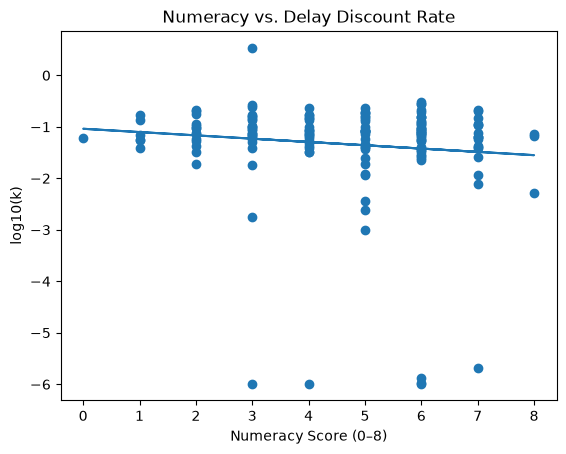

In [182]:
x = cognitive_interior["numeracy_score"]
y = cognitive_interior["log_k"]

slope, intercept = np.polyfit(x, y, 1)

plt.scatter(x, y)
plt.plot(x, slope * x + intercept)

plt.xlabel("Numeracy Score (0–8)")
plt.ylabel("log10(k)")
plt.title("Numeracy vs. Delay Discount Rate")

plt.show()

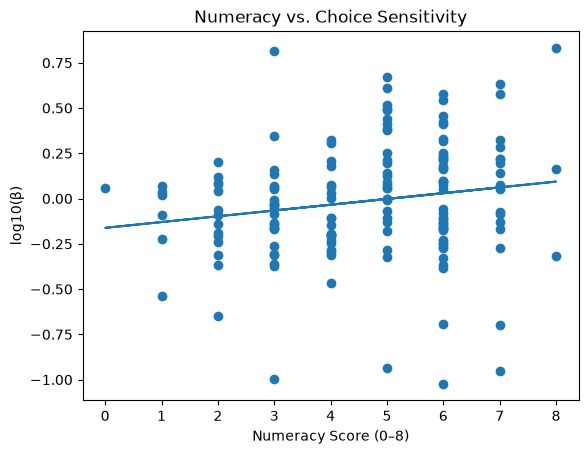

In [183]:
x = cognitive_interior["numeracy_score"]
y = cognitive_interior["log_beta"]

slope, intercept = np.polyfit(x, y, 1)

plt.scatter(x, y)
plt.plot(x, slope * x + intercept)

plt.xlabel("Numeracy Score (0–8)")
plt.ylabel("log10(β)")
plt.title("Numeracy vs. Choice Sensitivity")

plt.show()

### Numeracy and Delay Discounting

Numeracy showed a different pattern from working-memory capacity.

Among participants with interior parameter estimates, numeracy was not
significantly associated with the estimated discount rate (`k`)
(Pearson `r = -0.112`, `p = .162`; Spearman `ρ = -0.103`, `p = .200`).

However, higher numeracy was associated with greater estimated choice
sensitivity (`β`). This relationship was small but statistically significant
(Pearson `r = 0.176`, `p = .028`; Spearman `ρ = 0.204`, `p = .011`),
suggesting that participants with higher numeracy scores made choices that
were somewhat more consistently determined by differences in subjective value.

A behavioral robustness analysis using all 200 participants showed a clearer
relationship. Higher numeracy was associated with a lower rate of
smaller-sooner choices (Pearson `r = -0.290`, `p < .001`; Spearman
`ρ = -0.271`, `p < .001`).

Together, these results suggest that numeracy is associated with more
delayed-choice behavior and greater choice consistency, although this pattern
was not clearly captured by the estimated discount-rate parameter itself.

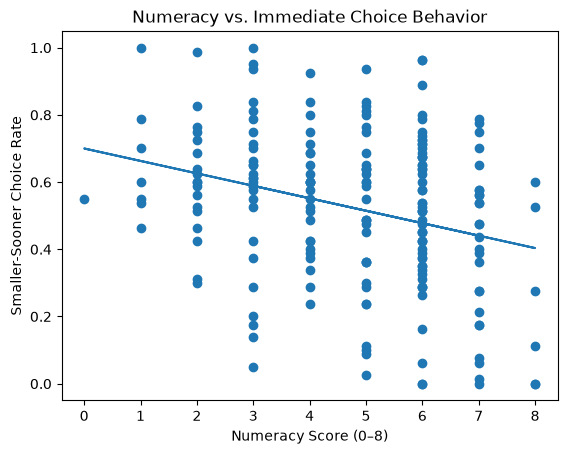

In [184]:
x = cognitive_df["numeracy_score"]
y = cognitive_df["ss_choice_rate"]

slope, intercept = np.polyfit(
    x,
    y,
    1
)

plt.scatter(x, y)

plt.plot(
    x,
    slope * x + intercept
)

plt.xlabel("Numeracy Score (0–8)")
plt.ylabel("Smaller-Sooner Choice Rate")
plt.title("Numeracy vs. Immediate Choice Behavior")

plt.show()

## Age and Delay Discounting

Age may be associated with intertemporal choice, cognitive performance, and
decision consistency. This section examines whether age relates to estimated
discount rate (`k`), choice sensitivity (`β`), numeracy, working memory, and
observed smaller-sooner choice behavior.

In [185]:
demographics_path = Path(
    "../data/raw/agerisk/demographics.csv"
)

demographics_df = pd.read_csv(
    demographics_path,
    na_values=["NA"]
)

In [186]:
demographics_clean = demographics_df[
    [
        "id",
        "age_ys_s1"
    ]
].rename(
    columns={
        "age_ys_s1": "age"
    }
)

cognitive_df = cognitive_df.merge(
    demographics_clean,
    on="id",
    how="inner",
    validate="one_to_one"
)

In [187]:
cognitive_interior = cognitive_df[
    ~cognitive_df["any_boundary"]
].copy()

In [188]:
age_k_pearson = pearsonr(
    cognitive_interior["age"],
    cognitive_interior["log_k"]
)

age_beta_pearson = pearsonr(
    cognitive_interior["age"],
    cognitive_interior["log_beta"]
)

age_ss_pearson = pearsonr(
    cognitive_df["age"],
    cognitive_df["ss_choice_rate"]
)

age_numeracy_pearson = pearsonr(
    cognitive_df["age"],
    cognitive_df["numeracy_score"]
)

age_ospan_pearson = pearsonr(
    cognitive_df["age"],
    cognitive_df["ospan_score"]
)

print("Age vs log10(k):", age_k_pearson)
print("Age vs log10(beta):", age_beta_pearson)
print("Age vs SS choice rate:", age_ss_pearson)
print("Age vs numeracy:", age_numeracy_pearson)
print("Age vs OSPAN:", age_ospan_pearson)

Age vs log10(k): PearsonRResult(statistic=np.float64(0.09048863505629239), pvalue=np.float64(0.2597117038531552))
Age vs log10(beta): PearsonRResult(statistic=np.float64(0.011891121427804798), pvalue=np.float64(0.882492787726961))
Age vs SS choice rate: PearsonRResult(statistic=np.float64(0.016873569142432182), pvalue=np.float64(0.8125408469594131))
Age vs numeracy: PearsonRResult(statistic=np.float64(-0.1954089101950577), pvalue=np.float64(0.005554878903943765))
Age vs OSPAN: PearsonRResult(statistic=np.float64(-0.38355823923489657), pvalue=np.float64(2.067735353500699e-08))


In [189]:
age_k_spearman = spearmanr(
    cognitive_interior["age"],
    cognitive_interior["log_k"]
)

age_beta_spearman = spearmanr(
    cognitive_interior["age"],
    cognitive_interior["log_beta"]
)

age_ss_spearman = spearmanr(
    cognitive_df["age"],
    cognitive_df["ss_choice_rate"]
)

age_numeracy_spearman = spearmanr(
    cognitive_df["age"],
    cognitive_df["numeracy_score"]
)

age_ospan_spearman = spearmanr(
    cognitive_df["age"],
    cognitive_df["ospan_score"]
)

print("Spearman age vs log10(k):", age_k_spearman)
print("Spearman age vs log10(beta):", age_beta_spearman)
print("Spearman age vs SS choice rate:", age_ss_spearman)
print("Spearman age vs numeracy:", age_numeracy_spearman)
print("Spearman age vs OSPAN:", age_ospan_spearman)

Spearman age vs log10(k): SignificanceResult(statistic=np.float64(-0.0631066794530975), pvalue=np.float64(0.43234292979966876))
Spearman age vs log10(beta): SignificanceResult(statistic=np.float64(0.007126073039149804), pvalue=np.float64(0.9294180555079269))
Spearman age vs SS choice rate: SignificanceResult(statistic=np.float64(-0.00393132799652194), pvalue=np.float64(0.9559400129090588))
Spearman age vs numeracy: SignificanceResult(statistic=np.float64(-0.17194145829263702), pvalue=np.float64(0.014910864794415899))
Spearman age vs OSPAN: SignificanceResult(statistic=np.float64(-0.3795445603409209), pvalue=np.float64(2.9779259987680563e-08))


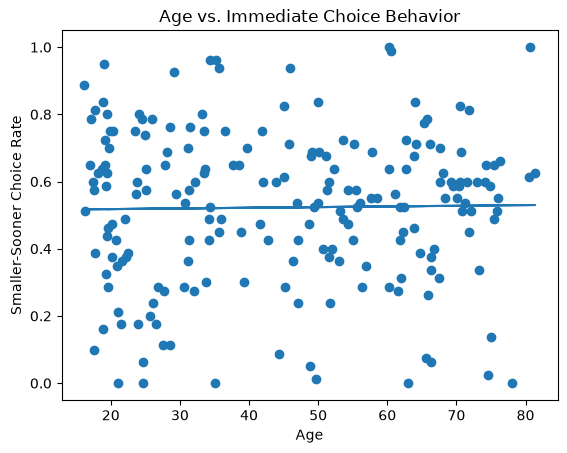

In [190]:
x = cognitive_df["age"]
y = cognitive_df["ss_choice_rate"]

slope, intercept = np.polyfit(
    x,
    y,
    1
)

plt.scatter(x, y)
plt.plot(
    x,
    slope * x + intercept
)

plt.xlabel("Age")
plt.ylabel("Smaller-Sooner Choice Rate")
plt.title("Age vs. Immediate Choice Behavior")

plt.show()

### Age and Delay Discounting

Age showed little relationship with delay-discounting behavior in this sample.
It was not significantly associated with estimated discount rate (`k`),
choice sensitivity (`β`), or observed smaller-sooner choice rate. Both Pearson
and Spearman correlations were close to zero.

Age was, however, negatively associated with cognitive performance. Older
participants tended to have lower numeracy scores (Pearson `r = -0.195`,
`p = .006`) and lower operation-span scores (Pearson `r = -0.384`,
`p < .001`). Similar relationships were observed using Spearman correlations.

These results suggest that age-related differences in cognitive performance
were present in the sample, but they did not translate into clear age-related
differences in delay-discounting behavior.

In [191]:
# Remove the linear association of age with numeracy
numeracy_age_fit = np.polyfit(
    cognitive_df["age"],
    cognitive_df["numeracy_score"],
    1
)

numeracy_residual = (
    cognitive_df["numeracy_score"]
    - (
        numeracy_age_fit[0] * cognitive_df["age"]
        + numeracy_age_fit[1]
    )
)

# Remove the linear association of age with SS choice rate
ss_age_fit = np.polyfit(
    cognitive_df["age"],
    cognitive_df["ss_choice_rate"],
    1
)

ss_residual = (
    cognitive_df["ss_choice_rate"]
    - (
        ss_age_fit[0] * cognitive_df["age"]
        + ss_age_fit[1]
    )
)

partial_numeracy_ss = pearsonr(
    numeracy_residual,
    ss_residual
)

print(
    "Numeracy vs SS choice rate, controlling for age:",
    partial_numeracy_ss
)

Numeracy vs SS choice rate, controlling for age: PearsonRResult(statistic=np.float64(-0.2928067783367996), pvalue=np.float64(2.5815900179532483e-05))


### Age-Adjusted Numeracy Association

Because age was negatively associated with numeracy, the relationship between
numeracy and smaller-sooner choice behavior was re-examined while controlling
for age.

The partial correlation remained essentially unchanged (`r = -0.293`,
`p < .001`). This indicates that the association between higher numeracy and
lower smaller-sooner choice rates was not explained by participants' age.

## Conclusion

This notebook examined whether individual differences in cognitive performance
were associated with delay-discounting behavior in the AgeRisk sample.

Working-memory capacity, measured using operation span, showed little evidence
of a relationship with intertemporal choice. Operation-span scores were
essentially unrelated to the estimated discount rate (`k`) and were also not
associated with the observed rate of smaller-sooner choices. A small positive
association with choice sensitivity (`β`) was observed, but the effect was weak.

Numeracy showed a clearer pattern. Higher numeracy was associated with greater
estimated choice sensitivity and with a lower rate of smaller-sooner choices.
The relationship with observed choice behavior remained significant after
controlling for age, suggesting that it was not simply explained by age-related
differences in cognitive performance.

Age itself was not meaningfully related to estimated discount rate, choice
sensitivity, or smaller-sooner choice behavior. However, older participants
tended to perform worse on both numeracy and operation-span measures, indicating
that age-related cognitive differences were present even though they did not
translate into clear age-related differences in delay discounting.

Overall, these results suggest that cognitive individual differences do not map
uniformly onto intertemporal choice. Working-memory capacity showed little
relationship with discounting behavior, whereas numeracy was more clearly
associated with delayed-choice behavior and greater choice consistency.

These findings are correlational and should not be interpreted as evidence that
numeracy or working-memory capacity causally changes delay-discounting behavior.
They also highlight an important modeling limitation: participant-level
parameter estimates were not well identified for all participants, so analyses
of `k` and `β` focused primarily on participants with interior estimates.